# Trabajando con texto

*John González*

**7 de noviembre de 2026**

La data no estructurada requiere un procesamiento muy especial. Por el auge del `Deep Learning` y los modelos de lenguaje (LLM), han surgido nuevos métodos. Actualmente se separan en dos paradigmas:

1. Se calcula una representación vectorial densa de los mismos (embeddings). Útil para análisis: agrupaciones, jerarquización. Ejemplo: En cuáles textos podría estar la respuesta a esta pregunta?
2. Se extraen entidades. Útil para obtener información inmediata. Ej: Extrae de este texto el sentimiento del mensaje.

Para trabajar ambos paradigmas vamos a instalar `ollama`. (https://ollama.com/download/)[Descárgalo de acuerdo a tu sistema operativo]. Por ejemplo, para Linux ejecuta desde la terminal:

```bash
curl -fsSL https://ollama.com/install.sh | sh
```

### Opcional: Para instalar Ollama en Debian/Ubuntu (GitHub CodeSpaces)

Sigue estos pasos desde una terminal:

1. Actualiza los índices de paquetes. Esto es importante si `apt` muestra **Unable to locate package**:

   ```bash
   sudo apt-get update
   ```

2. Instala `zstd`, que Ollama necesita para extraer sus archivos:

   ```bash
   sudo apt-get install -y zstd
   ```

3. Comprueba que `zstd` quedó instalado:

   ```bash
   zstd --version
   ```

4. Ejecuta el instalador oficial de Ollama:

   ```bash
   curl -fsSL https://ollama.com/install.sh | sh
   ```

5. Verifica la instalación:

   ```bash
   ollama --version
   ```

> Estos comandos deben ejecutarse en la terminal, no en una celda Python.

## Parte 1: Embeddings

Lee estos 3 tickets de una empresa muy importante:

* "El usuario está furioso por el cobro injusto en su factura."
* "Hubo un sobreprecio exagerado en la tarifa del servicio."
* "El vehículo llegó a la dirección indicada a las 8:00 AM."

Si quisiéramos filtrar en un motor tradicional o con un script de cadenas las frases que hablan de "Indignación por dinero", ¿qué regla de texto o consulta SQL (LIKE '%dinero%' o LIKE '%tarifa%') usarían?

El problema: La frase 1 y la frase 2 significan exactamente lo mismo, pero comparten cero palabras. La frase 3 no tiene nada que ver, pero podría compartir palabras clave secundarias.

### Instalación de embeddinggemma-2

Google publicó su modelo multimoldal de embeddings gemma-2. Con él puedes convertir cualquier dato no estructurado como imágenes, texto o video en una representación vectorial y realizar cosas interesantes como (https://x.com/googlegemma/status/2118036675540689044/video/1)[búsqueda por similitud].

Abra una terminal y escriba

```bash
ollama serve
```

y en otra diferente

```bash
ollama pull embeddinggemma-2
```


El modelo toma cualquier texto (un palabra, un párrafo, un libro entero, una imagen o un video) y lo convierte en una lista de números (un vector en $\mathbb{R}^d$, por ejemplo de 768 dimensiones). El modelo fue entrenado para que textos con significados parecidos apunten en direcciones similares en el espacio vectorial.

La similitud entre dos textos ya no se busca comparando letras, sino calculando el Producto Punto o la Similitud del Coseno:
$$\cos(\theta) = \frac{u \cdot v}{\Vert{}u\Vert{} \Vert{}v\Vert{}}$$

* Si dos vectores forman un ángulo de $0^\circ$ ($\cos=1$), dicen exactamente lo mismo sin importar qué palabras usaron.
* Si forman $90^\circ$ ($\cos=0$), no tienen ninguna relación semántica.


### Caso 1: Búsqueda Semántica por Cercanía (Semantic Search)

Un usuario busca en un buscador: "¿Dónde puedo dejar mi maleta?"

Solución:
* Convertimos la pregunta del usuario a un vector $V_{q}$.
* Calculamos el ángulo contra todos los documentos del Data Lake.
* El documento con el menor ángulo (mayor coseno) es la respuesta, aunque el documento diga "Conserva de equipaje en casilleros" y no contenga la palabra "maleta".

### Caso 2: Detección de Anomalías por Centroides (Clustering & Fraude)

Tienes 10,000 reportes de soporte técnico estándar. De repente entra un mensaje malicioso o fuera de lugar.
Solución: 
* Calculamos el vector promedio ($\bar{V}$, el centroide) del espacio de soporte.
* Cualquier mensaje cuyo vector esté a una distancia euclidiana excesiva del centroide es una anomalía semántica detectada automáticamente.

### Caso 3: Clasificación sin Entrenar Modelos (Zero-Shot Classification)

Quieres clasificar 100,000 textos en tres categorías: [Queja Mecánica, Cobro Excesivo, Buen Servicio].

Solución:
* Creamos el vector de cada etiqueta ($V_{mec}$, $V_{cob}$, $V_{serv}$).
* Para cada texto entrante, simplemente calculamos a cuál de los tres vectores etiqueta está más cerca.

En todos los casos tenemos clasificación automática sin entrenar modelos!

## Trabajando con los datos jiwsaw para identificar comentarios tóxicos

In [1]:
import kagglehub
from dotenv import load_dotenv

load_dotenv("../.env")

# Download latest version
path = kagglehub.competition_download('jigsaw-multilingual-toxic-comment-classification')

print("Path to competition files:", path)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 1.08G/1.08G [00:13<00:00, 85.2MB/s]


Extracting files...
Path to competition files: /home/vscode/.cache/kagglehub/competitions/jigsaw-multilingual-toxic-comment-classification


In [4]:
path = "/home/vscode/.cache/kagglehub/competitions/jigsaw-multilingual-toxic-comment-classification"

In [5]:
!ls {path}

jigsaw-toxic-comment-train-processed-seqlen128.csv
jigsaw-toxic-comment-train.csv
jigsaw-unintended-bias-train-processed-seqlen128.csv
jigsaw-unintended-bias-train.csv
sample_submission.csv
test-processed-seqlen128.csv
test.csv
test_labels.csv
validation-processed-seqlen128.csv
validation.csv


In [6]:
import polars as pl

SAMPLE_SIZE = 100

# 1. Excanear y tomar muestra aleatoria con 100 registros del archivo train.csv
ldf = pl.scan_csv(f"{path}/jigsaw-toxic-comment-train.csv")

# 2. Esquema de la tabla
ldf.schema

/tmp/ipykernel_1940/302823055.py:9: PerformanceWarning: Resolving the schema of a LazyFrame is a potentially expensive operation. Use `LazyFrame.collect_schema()` to get the schema without this warning.
  ldf.schema


Schema([('id', String),
        ('comment_text', String),
        ('toxic', Int64),
        ('severe_toxic', Int64),
        ('obscene', Int64),
        ('threat', Int64),
        ('insult', Int64),
        ('identity_hate', Int64)])

In [7]:
# Contar cantidad de filas

ldf.count().collect()

id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
u32,u32,u32,u32,u32,u32,u32,u32
223549,223549,223549,223549,223549,223549,223549,223549


In [19]:


# 2. Obtenemos el total de filas original de forma eficiente
total_rows = ldf.select(pl.len()).collect().item()
    
 
# 4. Aplicamos el filtro de muestreo determinista (10% de los datos usando legId)
# Usamos un seed en el hash para que sea reproducible
ldf_sample = ldf.filter((pl.col("id").hash(seed=42) % 10000) == 0)
 
ldf_sample.count().collect()
 
 

id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
u32,u32,u32,u32,u32,u32,u32,u32
23,23,23,23,23,23,23,23


In [20]:
# Veamos algunos comentarios

ldf_sample.head(10).collect()

id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
str,str,i64,i64,i64,i64,i64,i64
"""2650083300420930""","""Thanks Sandy! I don't think i…",0,0,0,0,0,0
"""49dd7ce6f636d3a5""","""Aecis, take a look at this his…",0,0,0,0,0,0
"""51db737a701bdac9""","""http://en.wikipedia.org/w/inde…",0,0,0,0,0,0
"""579bc8c2083e6f0f""","""November 2005 (UTC) Thank you…",0,0,0,0,0,0
"""709a95da3d409296""","""Unlike you I know the point of…",0,0,0,0,0,0
"""a4a16b9893bc7938""","""Mick Cooke I would like to he…",0,0,0,0,0,0
"""c2a23c7d8455b04f""","""review | action1result = list…",0,0,0,0,0,0
"""c5018cc06404e631""","""The cat is out of the bag. Use…",0,0,0,0,0,0
"""e90dc8b9e4b8f48c""","""Re-removal frackign stuff I'…",0,0,0,0,0,0


In [24]:
textos = ldf_sample.select("comment_text").collect().to_series().to_list()
etiquetas = ldf_sample.select("toxic").collect().to_series().to_list()

In [22]:
textos

["Thanks Sandy!  I don't think it would have gotten this far without your help!",
 'Aecis, take a look at this history on the talk page as well as the historyon the refactor pages (listed at the top).  After our anonymous friend was locked out of the article via semi-protect yesterday he decided to go on a talk page vandalism spree replacing everything in sight with the content of the article page edited to his liking.',
 "http://en.wikipedia.org/w/index.php?title=Talk:Patrolling&action;=edit\n\nI've edited intelligenceand subsituted information as intellegence is information that has been processed, and typically verified and cross refferenced with other sources.\n\nInformation on the other hand is just that raw information that has not been processed.\nPatrols collect information.\nThe information they collect is then processed and in conjunction with other information processed into intelligence.",
 'November 2005 (UTC)\n\nThank you ) It is very cute )  (talk (sr:)) 03:35, 11',
 'Un

## Representacion vectorial

In [ ]:
# Si falta alguna librería en tu entorno, instala con:
# pip install polars ollama scikit-learn matplotlib

import numpy as np
import ollama
from sklearn.decomposition import PCA

# VECTORIZACIÓN DE TEXTO CON OLLAMA (embeddinggema-2)
# ollama.embed procesa la lista en lote (batch) y devuelve una matriz (100, d)
print("Generando representaciones vectoriales...")
respuesta = ollama.embed(model="embeddinggemma-2", input=textos)
X_embeddings = np.array(respuesta["embeddings"])

print(f"Dimensión de la matriz de embeddings: {X_embeddings.shape}")


Generando representaciones vectoriales...
Dimensión de la matriz de embeddings: (23, 768)


In [ ]:
# 3. REDUCCIÓN DE DIMENSIONALIDAD (De R^d a R^2)
# Comparamos una proyección lineal (PCA) vs. una no lineal (t-SNE)
pca_2d = PCA(n_components=2, random_state=42).fit_transform(X_embeddings)


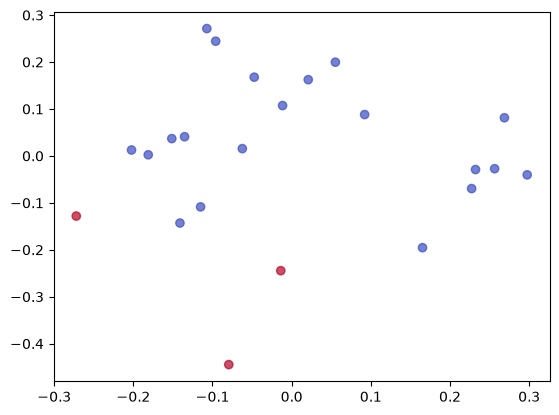

In [37]:
import matplotlib.pyplot as plt

plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=etiquetas, cmap='coolwarm', alpha=0.7)
plt.show()